<a href="https://colab.research.google.com/github/ananyamatta1112-crypto/Stellar-Photometry/blob/main/Photometry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install numpy==1.26.4
%pip install photutils==1.9.0

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

In [ ]:
from google.colab import files
files.upload()

In [ ]:
data = {
    '0':  'with_HWP_0.FIT',
    '22.5':  'with_HWP_22_5.FIT',
    '45': 'with_HWP_45.FIT',
    '67.5': 'with_HWP_67_5.FIT'}

In [ ]:
images = {k: fits.getdata(v, ignore_missing_simple=True) for k, v in data.items()}

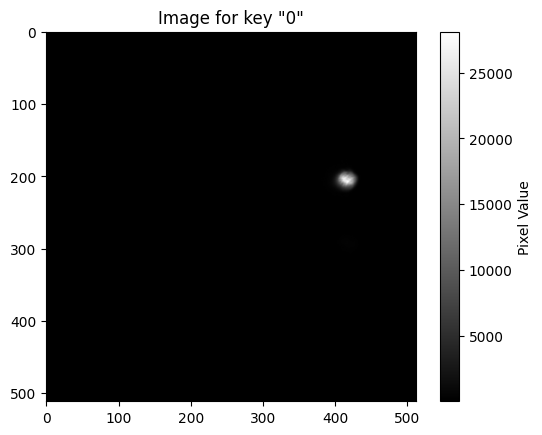

In [ ]:
plt.imshow(images['0'], cmap='gray')
plt.title('Image for key "0"')
plt.colorbar(label='Pixel Value')
plt.show()

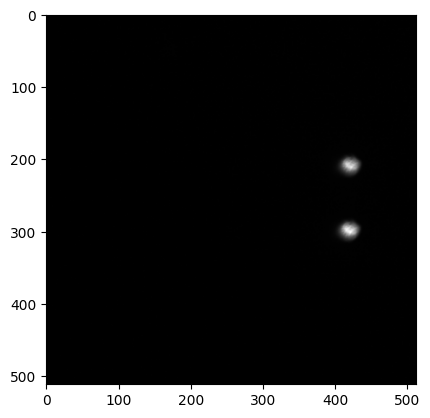

In [ ]:
plt.imshow(images['67.5'], cmap='gray')
plt.show()

center x, y =  [407.87686662] [202.53114984]


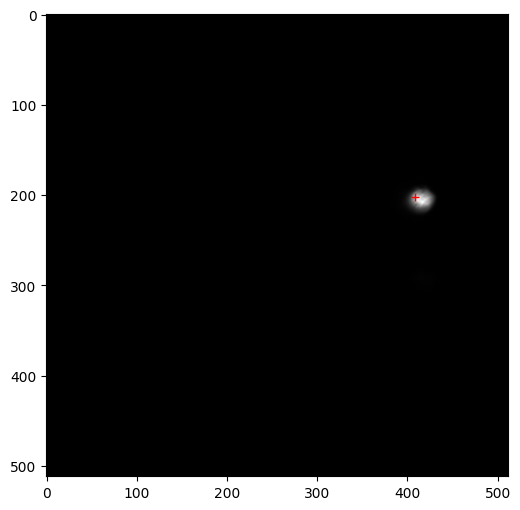

In [ ]:
x0, y0 = 380, 260
cutout = 31
from photutils.centroids import centroid_2dg, centroid_sources
x, y = centroid_sources(images['0'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)
print('center x, y = ',x,y)
plt.figure(figsize=(6,6))
plt.imshow(images['0'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['0']

In [ ]:
cutout_size = cutout
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1)
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1)

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 392, x_max: 423, y_min: 187, y_max: 218


/tmp/ipython-input-623457109.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-623457109.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape

x_indices = np.arange(nx)
y_indices = np.arange(ny)

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices)

x_data = x_mesh.ravel()
y_data = y_mesh.ravel()
z_data = star_cutout.ravel()

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 28110.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 27870.35
  x_mean: 23.35
  y_mean: 18.47
  x_stddev: 8.08
  y_stddev: 6.39


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 19.02
FWHM in y-direction: 15.04


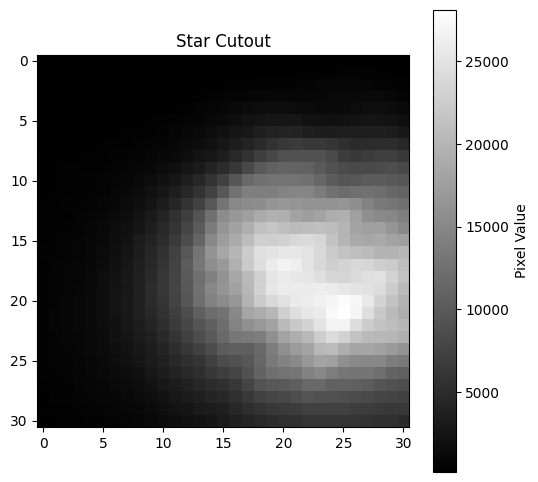

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 17.03


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 25.54


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=415.35, y=205.47
Aperture radius: 25.54
Inner annulus radius: 51.09
Outer annulus radius: 76.63


In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux0 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux0[0]:.2f}")

Raw aperture flux: 8837052.85
Mean background per pixel: 109.25
Total background in aperture: 223970.14
Background-subtracted flux: 8613082.71


Code 2

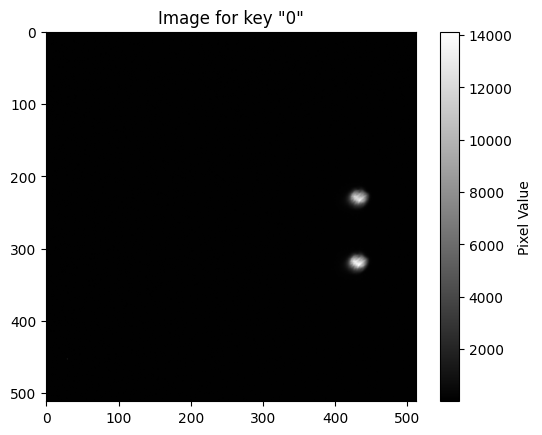

In [ ]:
plt.imshow(images['22.5'], cmap='gray')


plt.title('Image for key "0"')
plt.colorbar(label='Pixel Value')
plt.show()

center x, y =  [394.58205664] [173.3858329]


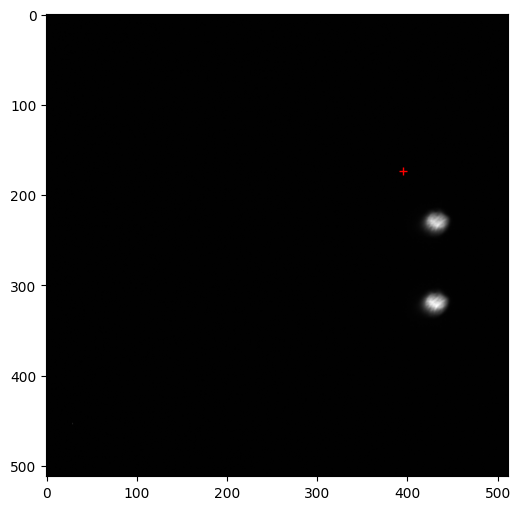

In [ ]:
x0, y0 = 380, 180 # rough guess for central coordinates of a star
cutout = 31 # subimage or cutout around x0, y0.

from photutils.centroids import centroid_2dg, centroid_sources

# centroid_2g will fit 2d gausssian arund x0,y0 to find exact cenetr

x, y = centroid_sources(images['22.5'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)

print('center x, y = ',x,y)

plt.figure(figsize=(6,6))
plt.imshow(images['22.5'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['22.5']

In [ ]:
cutout_size = cutout # Already defined as 31 from previous step
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

# Calculate min and max coordinates for the cutout, ensuring they stay within image bounds
x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1) # +1 because slicing is exclusive
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1) # +1 because slicing is exclusive

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 379, x_max: 410, y_min: 158, y_max: 189


/tmp/ipython-input-2146860284.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-2146860284.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape # Get dimensions of the star_cutout

x_indices = np.arange(nx) # Create 1D array for x-coordinates
y_indices = np.arange(ny) # Create 1D array for y-coordinates

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices) # Create 2D coordinate grids

x_data = x_mesh.ravel() # Flatten x_mesh into 1D array
y_data = y_mesh.ravel() # Flatten y_mesh into 1D array
z_data = star_cutout.ravel() # Flatten star_cutout into 1D array

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

# Initial guesses for Gaussian parameters
amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 144.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 393.76
  x_mean: 3139.51
  y_mean: 680.07
  x_stddev: 1988.28
  y_stddev: 66.80


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 4682.05
FWHM in y-direction: 157.31


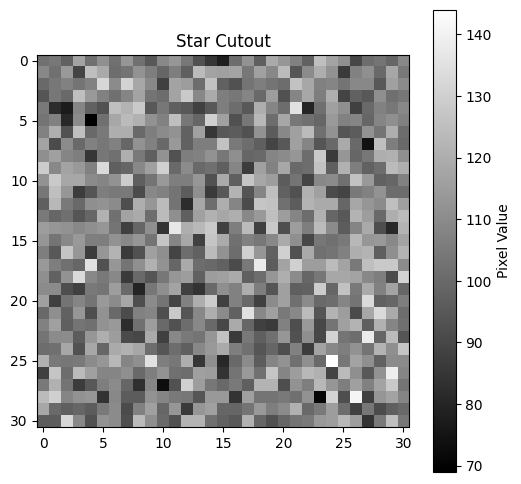

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 2419.68


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 3629.52


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=3518.51, y=838.07
Aperture radius: 3629.52
Inner annulus radius: 7259.03
Outer annulus radius: 10888.55


In [ ]:
aperture_radius = 23
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius
print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

Fitted star center in original image: x=3518.51, y=838.07
Aperture radius: 23.00
Inner annulus radius: 46.00
Outer annulus radius: 69.00


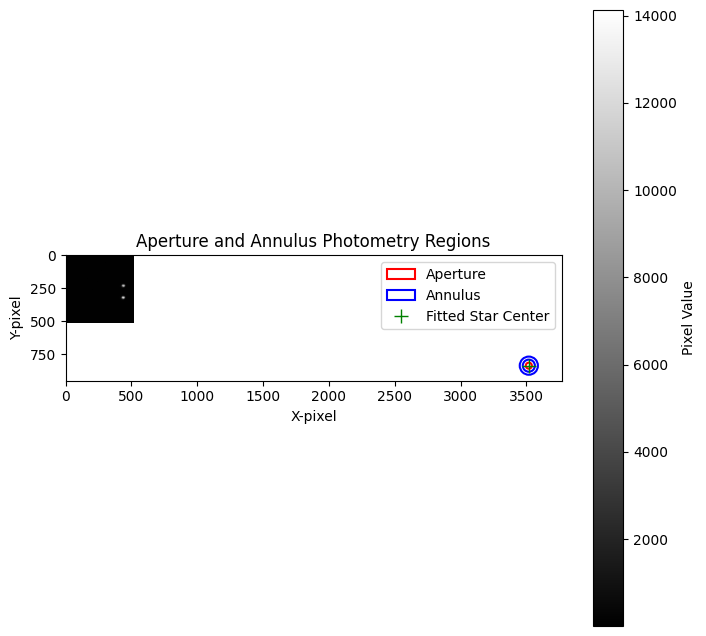

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(image, cmap='gray')
aperture.plot(color='red', lw=1.5, label='Aperture')
annulus_aperture.plot(color='blue', lw=1.5, label='Annulus')

# Optional: plot the fitted star center
plt.plot(fitted_x_image, fitted_y_image, 'g+', markersize=10, label='Fitted Star Center')

plt.title('Aperture and Annulus Photometry Regions')
plt.xlabel('X-pixel')
plt.ylabel('Y-pixel')
plt.legend()
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux2251 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux2251[0]:.2f}")

Raw aperture flux: nan
Mean background per pixel: nan
Total background in aperture: nan
Background-subtracted flux: nan


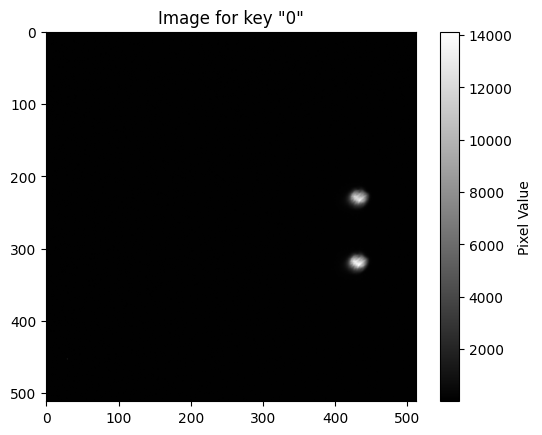

In [ ]:
plt.imshow(images['22.5'], cmap='gray')


plt.title('Image for key "0"')
plt.colorbar(label='Pixel Value')
plt.show()

center x, y =  [395.06045107] [281.42294684]


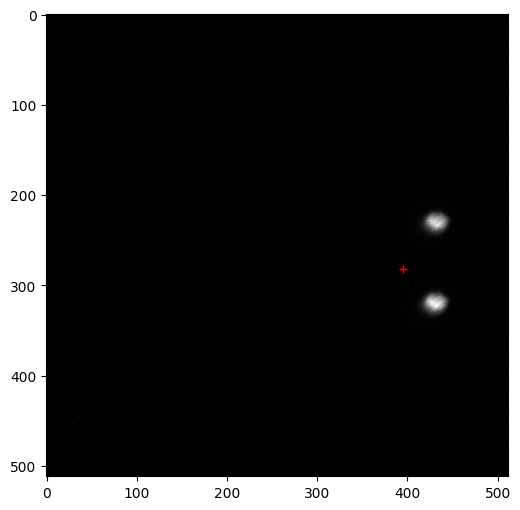

In [ ]:
x0, y0 = 380, 280 # rough guess for central coordinates of a star
cutout = 31 # subimage or cutout around x0, y0.

from photutils.centroids import centroid_2dg, centroid_sources

# centroid_2g will fit 2d gausssian arund x0,y0 to find exact cenetr

x, y = centroid_sources(images['22.5'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)

print('center x, y = ',x,y)

plt.figure(figsize=(6,6))
plt.imshow(images['22.5'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['22.5']

In [ ]:
cutout_size = cutout # Already defined as 31 from previous step
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

# Calculate min and max coordinates for the cutout, ensuring they stay within image bounds
x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1) # +1 because slicing is exclusive
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1) # +1 because slicing is exclusive

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 380, x_max: 411, y_min: 266, y_max: 297


/tmp/ipython-input-2146860284.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-2146860284.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape # Get dimensions of the star_cutout

x_indices = np.arange(nx) # Create 1D array for x-coordinates
y_indices = np.arange(ny) # Create 1D array for y-coordinates

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices) # Create 2D coordinate grids

x_data = x_mesh.ravel() # Flatten x_mesh into 1D array
y_data = y_mesh.ravel() # Flatten y_mesh into 1D array
z_data = star_cutout.ravel() # Flatten star_cutout into 1D array

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

# Initial guesses for Gaussian parameters
amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 152.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 425.88
  x_mean: 1140.03
  y_mean: 1181.03
  x_stddev: 995.00
  y_stddev: 127.62


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 2343.04
FWHM in y-direction: 300.52


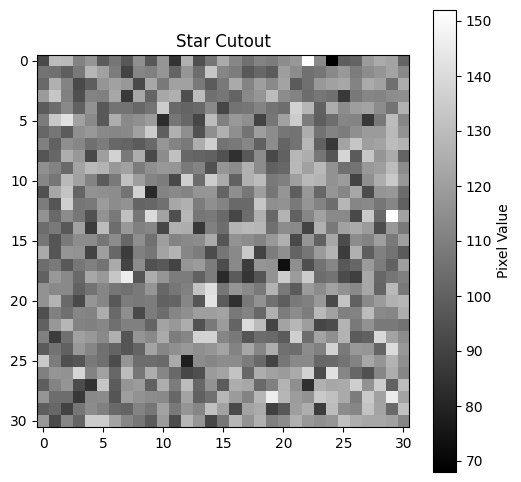

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 1321.78


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 1982.67


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=1520.03, y=1447.03
Aperture radius: 1982.67
Inner annulus radius: 3965.33
Outer annulus radius: 5948.00


In [ ]:
aperture_radius = 23
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius
print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

Fitted star center in original image: x=1520.03, y=1447.03
Aperture radius: 23.00
Inner annulus radius: 46.00
Outer annulus radius: 69.00


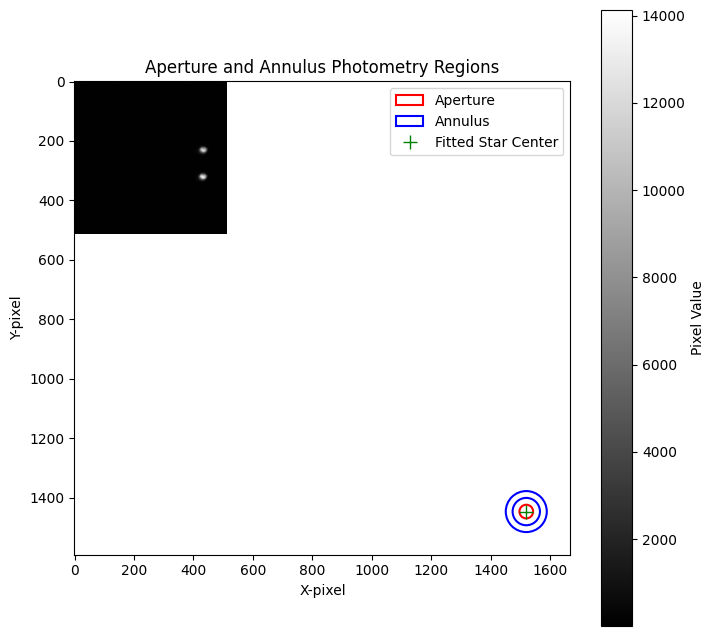

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(image, cmap='gray')
aperture.plot(color='red', lw=1.5, label='Aperture')
annulus_aperture.plot(color='blue', lw=1.5, label='Annulus')

# Optional: plot the fitted star center
plt.plot(fitted_x_image, fitted_y_image, 'g+', markersize=10, label='Fitted Star Center')

plt.title('Aperture and Annulus Photometry Regions')
plt.xlabel('X-pixel')
plt.ylabel('Y-pixel')
plt.legend()
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux2252 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux2252[0]:.2f}")

Raw aperture flux: nan
Mean background per pixel: nan
Total background in aperture: nan
Background-subtracted flux: nan


Code 3

center x, y =  [346.45266966] [128.80140421]


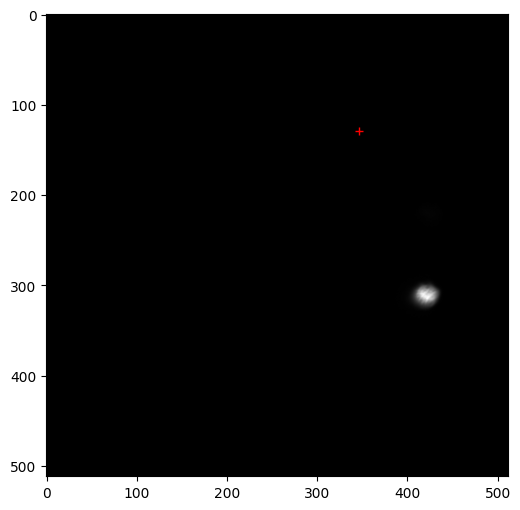

In [ ]:
x0, y0 = 380, 180 # rough guess for central coordinates of a star
cutout = 31 # subimage or cutout around x0, y0.

from photutils.centroids import centroid_2dg, centroid_sources

# centroid_2g will fit 2d gausssian arund x0,y0 to find exact cenetr

x, y = centroid_sources(images['45'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)

print('center x, y = ',x,y)

plt.figure(figsize=(6,6))
plt.imshow(images['45'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['45']

In [ ]:
cutout_size = cutout # Already defined as 31 from previous step
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

# Calculate min and max coordinates for the cutout, ensuring they stay within image bounds
x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1) # +1 because slicing is exclusive
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1) # +1 because slicing is exclusive

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 331, x_max: 362, y_min: 113, y_max: 144


/tmp/ipython-input-2146860284.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-2146860284.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape # Get dimensions of the star_cutout

x_indices = np.arange(nx) # Create 1D array for x-coordinates
y_indices = np.arange(ny) # Create 1D array for y-coordinates

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices) # Create 2D coordinate grids

x_data = x_mesh.ravel() # Flatten x_mesh into 1D array
y_data = y_mesh.ravel() # Flatten y_mesh into 1D array
z_data = star_cutout.ravel() # Flatten star_cutout into 1D array

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

# Initial guesses for Gaussian parameters
amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 137.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 186.13
  x_mean: -1323.03
  y_mean: -472.95
  x_stddev: 1317.59
  y_stddev: 122.10


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 3102.68
FWHM in y-direction: 287.52


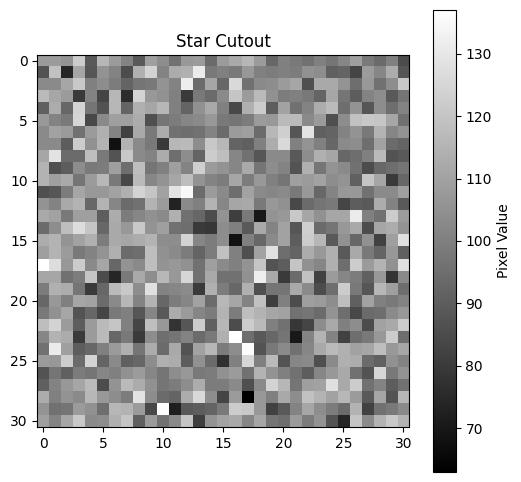

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 1695.10


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 2542.65


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=-992.03, y=-359.95
Aperture radius: 2542.65
Inner annulus radius: 5085.30
Outer annulus radius: 7627.95


In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux45 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux45[0]:.2f}")

Raw aperture flux: 35463889.00
Mean background per pixel: 0.00
Total background in aperture: 0.00
Background-subtracted flux: 35463889.00


Code 4

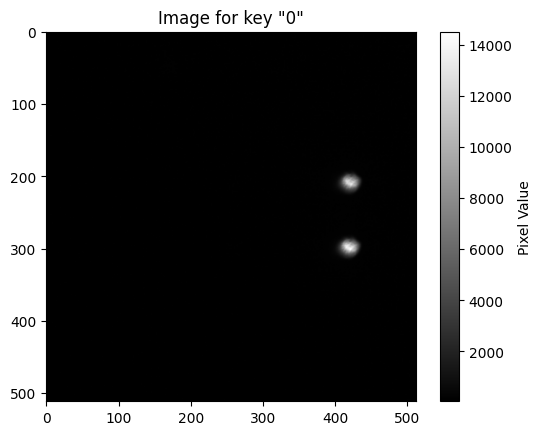

In [ ]:
plt.imshow(images['67.5'], cmap='gray')


plt.title('Image for key "0"')
plt.colorbar(label='Pixel Value')
plt.show()

center x, y =  [372.83386732] [169.32190548]


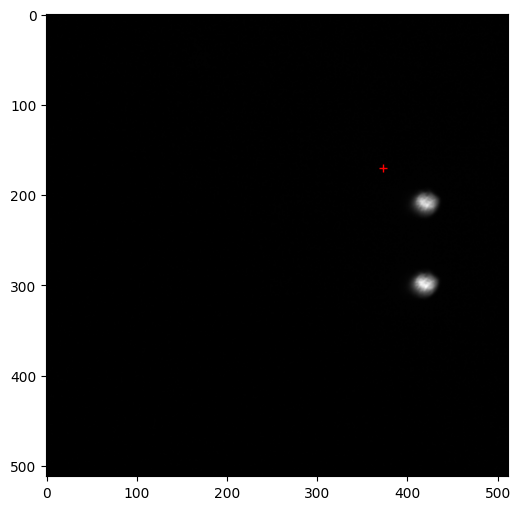

In [ ]:
x0, y0 = 380, 180 # rough guess for central coordinates of a star
cutout = 31 # subimage or cutout around x0, y0.

from photutils.centroids import centroid_2dg, centroid_sources

# centroid_2g will fit 2d gausssian arund x0,y0 to find exact cenetr

x, y = centroid_sources(images['67.5'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)

print('center x, y = ',x,y)

plt.figure(figsize=(6,6))
plt.imshow(images['67.5'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['67.5']

In [ ]:
cutout_size = cutout # Already defined as 31 from previous step
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

# Calculate min and max coordinates for the cutout, ensuring they stay within image bounds
x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1) # +1 because slicing is exclusive
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1) # +1 because slicing is exclusive

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 357, x_max: 388, y_min: 154, y_max: 185


/tmp/ipython-input-2146860284.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-2146860284.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape # Get dimensions of the star_cutout

x_indices = np.arange(nx) # Create 1D array for x-coordinates
y_indices = np.arange(ny) # Create 1D array for y-coordinates

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices) # Create 2D coordinate grids

x_data = x_mesh.ravel() # Flatten x_mesh into 1D array
y_data = y_mesh.ravel() # Flatten y_mesh into 1D array
z_data = star_cutout.ravel() # Flatten star_cutout into 1D array

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

# Initial guesses for Gaussian parameters
amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 157.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 116.58
  x_mean: 18.92
  y_mean: 22.59
  x_stddev: 76.58
  y_stddev: 223.58


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 180.33
FWHM in y-direction: 526.50


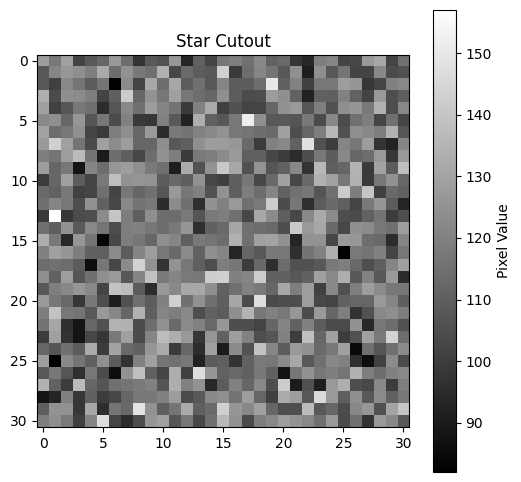

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 353.42


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 530.12


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=375.92, y=176.59
Aperture radius: 530.12
Inner annulus radius: 1060.25
Outer annulus radius: 1590.37


In [ ]:
aperture_radius = 23
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius
print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

Fitted star center in original image: x=375.92, y=176.59
Aperture radius: 23.00
Inner annulus radius: 46.00
Outer annulus radius: 69.00


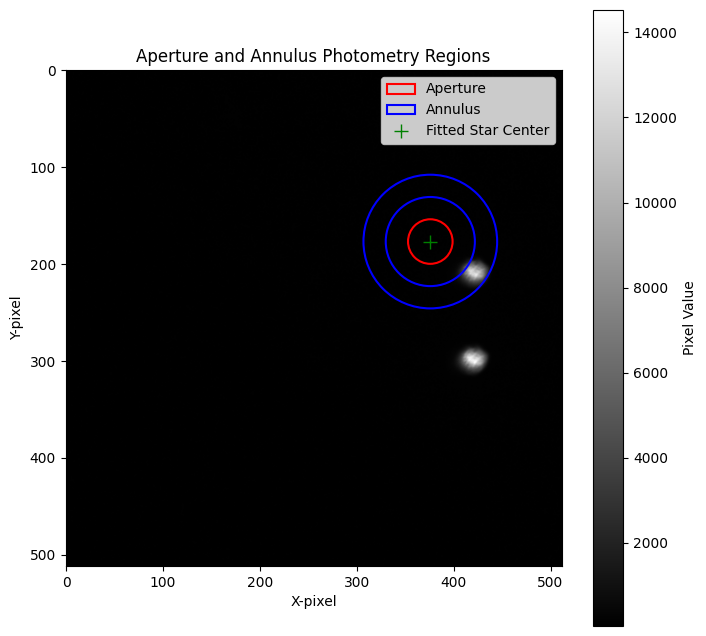

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(image, cmap='gray')
aperture.plot(color='red', lw=1.5, label='Aperture')
annulus_aperture.plot(color='blue', lw=1.5, label='Annulus')

# Optional: plot the fitted star center
plt.plot(fitted_x_image, fitted_y_image, 'g+', markersize=10, label='Fitted Star Center')

plt.title('Aperture and Annulus Photometry Regions')
plt.xlabel('X-pixel')
plt.ylabel('Y-pixel')
plt.legend()
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux6751 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux6751[0]:.2f}")

Raw aperture flux: 195503.58
Mean background per pixel: 550.64
Total background in aperture: 915110.89
Background-subtracted flux: -719607.32


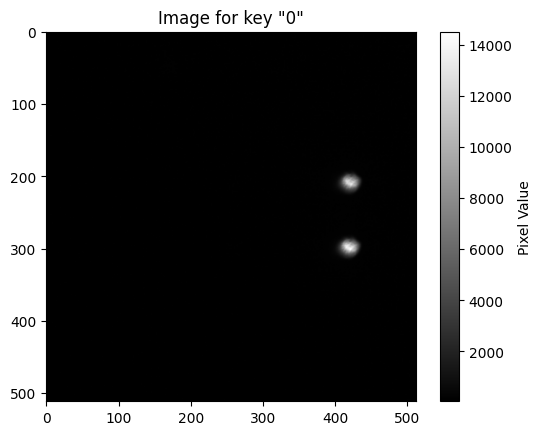

In [ ]:
plt.imshow(images['67.5'], cmap='gray')


plt.title('Image for key "0"')
plt.colorbar(label='Pixel Value')
plt.show()

center x, y =  [347.80037368] [253.21185162]


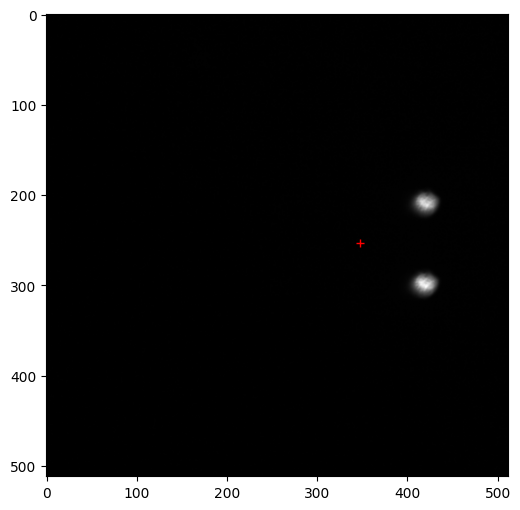

In [ ]:
x0, y0 = 380, 280 # rough guess for central coordinates of a star
cutout = 31 # subimage or cutout around x0, y0.

from photutils.centroids import centroid_2dg, centroid_sources

# centroid_2g will fit 2d gausssian arund x0,y0 to find exact cenetr

x, y = centroid_sources(images['67.5'], x0, y0, box_size=cutout, centroid_func=centroid_2dg)

print('center x, y = ',x,y)

plt.figure(figsize=(6,6))
plt.imshow(images['67.5'], cmap='gray')
plt.plot(x,y, 'r+')
plt.show()

In [ ]:
image = images['67.5']

In [ ]:
cutout_size = cutout # Already defined as 31 from previous step
half_cutout = int(cutout_size / 2)

x_center = int(x)
y_center = int(y)

# Calculate min and max coordinates for the cutout, ensuring they stay within image bounds
x_min = max(0, x_center - half_cutout)
x_max = min(image.shape[1], x_center + half_cutout + 1) # +1 because slicing is exclusive
y_min = max(0, y_center - half_cutout)
y_max = min(image.shape[0], y_center + half_cutout + 1) # +1 because slicing is exclusive

star_cutout = image[y_min:y_max, x_min:x_max]

print(f"Star cutout shape: {star_cutout.shape}")
print(f"Cutout x_min: {x_min}, x_max: {x_max}, y_min: {y_min}, y_max: {y_max}")


Star cutout shape: (31, 31)
Cutout x_min: 332, x_max: 363, y_min: 238, y_max: 269


/tmp/ipython-input-2146860284.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x_center = int(x)
/tmp/ipython-input-2146860284.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_center = int(y)


In [ ]:
ny, nx = star_cutout.shape # Get dimensions of the star_cutout

x_indices = np.arange(nx) # Create 1D array for x-coordinates
y_indices = np.arange(ny) # Create 1D array for y-coordinates

x_mesh, y_mesh = np.meshgrid(x_indices, y_indices) # Create 2D coordinate grids

x_data = x_mesh.ravel() # Flatten x_mesh into 1D array
y_data = y_mesh.ravel() # Flatten y_mesh into 1D array
z_data = star_cutout.ravel() # Flatten star_cutout into 1D array

print(f"Shape of x_mesh: {x_mesh.shape}")
print(f"Shape of y_mesh: {y_mesh.shape}")
print(f"Shape of z_data (flattened cutout): {z_data.shape}")

Shape of x_mesh: (31, 31)
Shape of y_mesh: (31, 31)
Shape of z_data (flattened cutout): (961,)


In [ ]:
from astropy.modeling.models import Gaussian2D
from astropy.modeling.fitting import LevMarLSQFitter

# Initial guesses for Gaussian parameters
amplitude_guess = np.max(star_cutout) # Use the maximum pixel value as initial amplitude
x_mean_guess = nx / 2.0 # Center of the cutout in x
y_mean_guess = ny / 2.0 # Center of the cutout in y
x_stddev_guess = 2.0 # Initial guess for standard deviation in x
y_stddev_guess = 2.0 # Initial guess for standard deviation in y

# Define the 2D Gaussian model with initial guesses
g_init = Gaussian2D(amplitude=amplitude_guess, x_mean=x_mean_guess, y_mean=y_mean_guess,
                     x_stddev=x_stddev_guess, y_stddev=y_stddev_guess)

print(f"Initial Gaussian parameters: ")
print(f"  Amplitude: {g_init.amplitude.value}")
print(f"  x_mean: {g_init.x_mean.value}")
print(f"  y_mean: {g_init.y_mean.value}")
print(f"  x_stddev: {g_init.x_stddev.value}")
print(f"  y_stddev: {g_init.y_stddev.value}")

Initial Gaussian parameters: 
  Amplitude: 149.0
  x_mean: 15.5
  y_mean: 15.5
  x_stddev: 2.0
  y_stddev: 2.0


In [ ]:
fitter = LevMarLSQFitter() # Initialize the fitter
g_fit = fitter(g_init, x_data, y_data, z_data) # Fit the model to the data

print(f"Fitted Gaussian parameters:")
print(f"  Amplitude: {g_fit.amplitude.value:.2f}")
print(f"  x_mean: {g_fit.x_mean.value:.2f}")
print(f"  y_mean: {g_fit.y_mean.value:.2f}")
print(f"  x_stddev: {g_fit.x_stddev.value:.2f}")
print(f"  y_stddev: {g_fit.y_stddev.value:.2f}")

Fitted Gaussian parameters:
  Amplitude: 114.15
  x_mean: 41.09
  y_mean: -0.87
  x_stddev: 202.60
  y_stddev: 97.76


In [ ]:
fwhm_x = 2 * np.sqrt(2 * np.log(2)) * g_fit.x_stddev.value
fwhm_y = 2 * np.sqrt(2 * np.log(2)) * g_fit.y_stddev.value

print(f"FWHM in x-direction: {fwhm_x:.2f}")
print(f"FWHM in y-direction: {fwhm_y:.2f}")

FWHM in x-direction: 477.09
FWHM in y-direction: 230.21


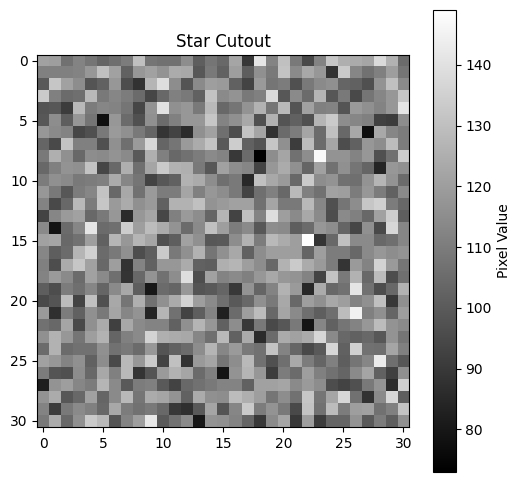

In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(star_cutout, cmap='gray')
plt.title('Star Cutout')
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
fwhm_avg = np.mean([fwhm_x, fwhm_y])

print(f"Average FWHM: {fwhm_avg:.2f}")

Average FWHM: 353.65


In [ ]:
aperture_radius = 1.5 * fwhm_avg
print(f"Aperture radius: {aperture_radius:.2f}")

Aperture radius: 530.48


In [ ]:
fitted_x_image = x_min + g_fit.x_mean.value
fitted_y_image = y_min + g_fit.y_mean.value

positions = [(fitted_x_image, fitted_y_image)]

# Define background annulus radii
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius

# Create aperture and annulus objects
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")

Fitted star center in original image: x=373.09, y=237.13
Aperture radius: 530.48
Inner annulus radius: 1060.95
Outer annulus radius: 1591.43


In [ ]:
aperture_radius = 23
inner_annulus_radius = 2.0 * aperture_radius
outer_annulus_radius = 3.0 * aperture_radius
print(f"Fitted star center in original image: x={fitted_x_image:.2f}, y={fitted_y_image:.2f}")
print(f"Aperture radius: {aperture_radius:.2f}")
print(f"Inner annulus radius: {inner_annulus_radius:.2f}")
print(f"Outer annulus radius: {outer_annulus_radius:.2f}")
aperture = CircularAperture(positions, r=aperture_radius)
annulus_aperture = CircularAnnulus(positions, r_in=inner_annulus_radius, r_out=outer_annulus_radius)

Fitted star center in original image: x=373.09, y=237.13
Aperture radius: 23.00
Inner annulus radius: 46.00
Outer annulus radius: 69.00


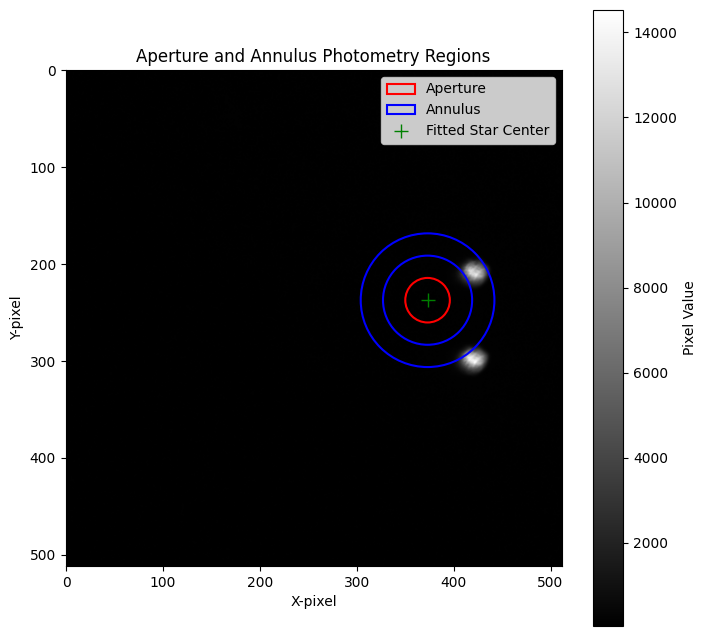

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(image, cmap='gray')
aperture.plot(color='red', lw=1.5, label='Aperture')
annulus_aperture.plot(color='blue', lw=1.5, label='Annulus')

# Optional: plot the fitted star center
plt.plot(fitted_x_image, fitted_y_image, 'g+', markersize=10, label='Fitted Star Center')

plt.title('Aperture and Annulus Photometry Regions')
plt.xlabel('X-pixel')
plt.ylabel('Y-pixel')
plt.legend()
plt.colorbar(label='Pixel Value')
plt.show()

In [ ]:
phot_table = aperture_photometry(image, aperture)
annulus_phot_table = aperture_photometry(image, annulus_aperture)

# Calculate mean background in the annulus
b_mean = annulus_phot_table['aperture_sum'] / annulus_aperture.area

# Calculate total background in the aperture
b_sum = b_mean * aperture.area

# Calculate background-subtracted flux
final_flux6752 = phot_table['aperture_sum'] - b_sum

print(f"Raw aperture flux: {phot_table['aperture_sum'][0]:.2f}")
print(f"Mean background per pixel: {b_mean[0]:.2f}")
print(f"Total background in aperture: {b_sum[0]:.2f}")
print(f"Background-subtracted flux: {final_flux6752[0]:.2f}")

Raw aperture flux: 195497.65
Mean background per pixel: 609.94
Total background in aperture: 1013658.41
Background-subtracted flux: -818160.76


In [ ]:
flux_0=final_flux0
flux_225_0=final_flux2251
flux_225_e=final_flux2252
flux_45=final_flux45
flux_675_0=final_flux6751
flux_675_e=final_flux6752

In [ ]:
R_0 = flux_0 / flux_45
R_225 = (flux_225_0 - flux_225_e) / (flux_225_0 + flux_225_e)

print(f"Degree of polarisation: {R_0[0]:.2f}")
AoP = 0.5 * np.degrees(np.arctan2(R_225, R_0))
print(f"Angle of Polarization (AoP): {AoP[0]:.4f} degrees")

Degree of polarisation: 0.24
Angle of Polarization (AoP): nan degrees
